<a href="https://colab.research.google.com/github/CharlestonGit/Assignment-1-web/blob/main/cyber_assignment_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

df = pd.read_csv('/content/simple_cyber_messages.csv')
display(df.head(10))
print('Dataset shape:',df.shape)


,message_id,message,correct_category
0,1,The department meeting is scheduled for 2 PM i...,Safe
1,2,Your account will be suspended. Click here and...,Phishing
2,3,The attached executable file contains a trojan...,Malware
3,4,Your files have been encrypted. Pay bitcoin to...,Ransomware
4,5,Library books must be returned before Friday.,Safe
5,6,Congratulations! You won a prize. Login now to...,Phishing
6,7,Antivirus detected spyware in the downloaded a...,Malware
7,8,Locked files will be released only after ranso...,Ransomware
8,9,Your monthly attendance report is available on...,Safe
9,10,Urgent bank alert: verify account and share OT...,Phishing


Dataset shape: (28, 3)


In [ ]:
manual_table = df.head(10)[
    ['message_id', 'message', 'correct_category']
    ].copy()
# TODO: Add important words for each of the ten messages
manual_table['important_words'] = [
    'meeting, scheduled',
     'suspended, click here, verify, password, urgently',
     'executable, trojan, infect',
    'encrypted, bitcoin, restore files',
     'library, returned',
     'prize, login, claim',
    'spyware, attachment',
     'locked files, ransom, payment',
     'official portal',
    'urgent, bank, verify, OTP'
]
display(manual_table)


,message_id,message,correct_category,important_words
0,1,The department meeting is scheduled for 2 PM i...,Safe,"meeting, scheduled"
1,2,Your account will be suspended. Click here and...,Phishing,"suspended, click here, verify, password, urgently"
2,3,The attached executable file contains a trojan...,Malware,"executable, trojan, infect"
3,4,Your files have been encrypted. Pay bitcoin to...,Ransomware,"encrypted, bitcoin, restore files"
4,5,Library books must be returned before Friday.,Safe,"library, returned"
5,6,Congratulations! You won a prize. Login now to...,Phishing,"prize, login, claim"
6,7,Antivirus detected spyware in the downloaded a...,Malware,"spyware, attachment"
7,8,Locked files will be released only after ranso...,Ransomware,"locked files, ransom, payment"
8,9,Your monthly attendance report is available on...,Safe,official portal
9,10,Urgent bank alert: verify account and share OT...,Phishing,"urgent, bank, verify, OTP"


In [ ]:
RULE_KEYWORDS = {
    "Phishing": [
        "click here",
        "verify",
        "password",
        "urgent",
        "otp",
        "prize",
        "bank",
        "login",
        "blocked"
    ],

    "Malware": [
        "malware",
        "virus",
        "infected",
        "attachment",
        "trojan",
        "spyware",
        "executable"
    ],

    "Ransomware": [
        "encrypted",
        "ransom",
        "bitcoin",
        "restore files",
        "locked files",
        "unlock",
        "payment demand"
    ]
}


def classify_message(text):
    # Convert message to lowercase
    text = str(text).lower()

    # Calculate keyword matches for each category
    scores = {
        category: sum(word in text for word in keywords)
        for category, keywords in RULE_KEYWORDS.items()
    }

    # Find category with highest score
    predicted = max(scores, key=scores.get)

    # If no keywords were found
    if scores[predicted] == 0:
        return "Safe", "", 0

    # Find the keywords that matched
    matched = [
        word
        for word in RULE_KEYWORDS[predicted]
        if word in text
    ]

    return predicted, ", ".join(matched), scores[predicted]


# Test the classifier
result = classify_message(
    "Urgent: click here to verify your password"
)

print(result)

('Phishing', 'click here, verify, password, urgent', 4)


In [ ]:
# Create empty lists to store the prediction results
predicted_categories = []
matched_keywords_list = []
keyword_scores = []

# Read each message from the 'message' column
for message in df['message']:

    # Classify the current message
    # The function returns category, matched keywords, and score
    category, matched_keywords, score = classify_message(message)

    # Store the predicted category
    predicted_categories.append(category)

    # Store the matched keywords
    matched_keywords_list.append(matched_keywords)

    # Store the keyword score
    keyword_scores.append(score)


# Add predicted categories as a new DataFrame column
df['predicted_category'] = predicted_categories

# Add matched keywords as a new DataFrame column
df['matched_keywords'] = matched_keywords_list

# Add keyword scores as a new DataFrame column
df['keyword_score'] = keyword_scores


# Create a column to check whether each prediction is correct
df['correct'] = (
    df['correct_category'] == df['predicted_category']
)


# Count the total number of correct predictions
correct_predictions = df['correct'].sum()

# Count the total number of incorrect predictions
incorrect_predictions = len(df) - correct_predictions


# Calculate accuracy
accuracy = correct_predictions / len(df)


# Select the columns that we want to display
output_columns = [
    'message_id',
    'correct_category',
    'predicted_category',
    'matched_keywords',
    'correct'
]


# Display the selected columns
display(df[output_columns])


# Print the number of correct predictions
print('Correct predictions:', correct_predictions)

# Print the number of incorrect predictions
print('Incorrect predictions:', incorrect_predictions)

# Print accuracy as a percentage with two decimal places
print(f'Accuracy: {accuracy * 100:.2f}%')

,message_id,correct_category,predicted_category,matched_keywords,correct
0,1,Safe,Safe,,True
1,2,Phishing,Phishing,"click here, verify, password, urgent",True
2,3,Malware,Malware,"trojan, executable",True
3,4,Ransomware,Ransomware,"encrypted, bitcoin, restore files",True
4,5,Safe,Safe,,True
5,6,Phishing,Phishing,"prize, login",True
6,7,Malware,Malware,"virus, attachment, spyware",True
7,8,Ransomware,Ransomware,"ransom, locked files",True
8,9,Safe,Safe,,True
9,10,Phishing,Phishing,"verify, urgent, otp, bank",True


Correct predictions: 27
Incorrect predictions: 1
Accuracy: 96.43%


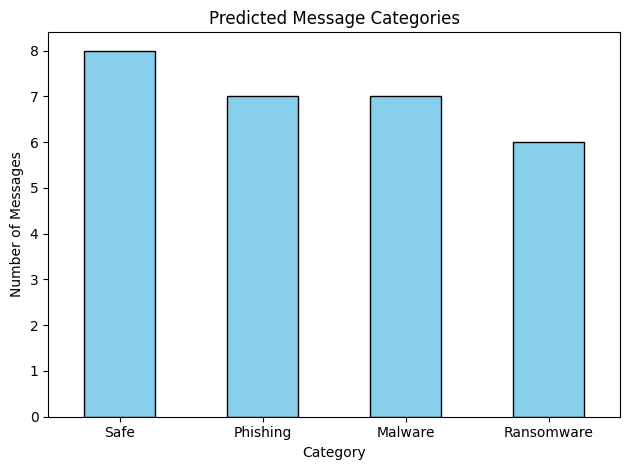

In [ ]:
# Create empty lists to store risk levels and recommended actions
risk_levels = []
recommended_actions = []

# Read each row of the DataFrame one by one
for index, row in df.iterrows():

    # Get the predicted category of the current message
    category = row['predicted_category']

    # Get the keyword score of the current message
    score = row['keyword_score']

    # If the message is safe, assign a low risk level
    if category == 'Safe':
        risk = 'Low'
        action = 'Continue normal caution.'

    # If the message is ransomware or has two or more risky keywords,
    # assign a high risk level
    elif category == 'Ransomware' or score >= 2:
        risk = 'High'
        action = 'Do not click/open; isolate if required and report.'

    # Assign medium risk to all other suspicious messages
    else:
        risk = 'Medium'
        action = 'Do not interact; verify the sender and report.'

    # Store the risk level in the list
    risk_levels.append(risk)

    # Store the recommended action in the list
    recommended_actions.append(action)


# Add the risk levels as a new DataFrame column
df['risk_level'] = risk_levels

# Add the recommended actions as a new DataFrame column
df['recommended_action'] = recommended_actions


# Set the order in which categories should appear in the graph
category_order = [
    'Safe',
    'Phishing',
    'Malware',
    'Ransomware'
]


# Count the number of messages in each predicted category
category_counts = df['predicted_category'].value_counts()


# Arrange the categories in the required order
# If a category is missing, its count will be set to 0
category_counts = category_counts.reindex(
    category_order,
    fill_value=0
)


# Create a bar graph of the predicted message categories
category_counts.plot(
    kind='bar',
    color='skyblue',
    edgecolor='black'
)


# Add a title to the graph
plt.title('Predicted Message Categories')

# Add a label to the horizontal axis
plt.xlabel('Category')

# Add a label to the vertical axis
plt.ylabel('Number of Messages')

# Keep the category labels horizontal
plt.xticks(rotation=0)

# Adjust spacing so that all graph elements are visible
plt.tight_layout()

# Display the graph
plt.show()

In [ ]:
# Create a list of responsible-use points
responsible_use = [
    'Privacy: remove personal identifiers before analysis.',
    'Bias: keyword lists may not cover every writing style.',
    'False alarms: safe messages may contain warning words.',
    'Accountability: humans remain responsible for action.',
    'Human review: high-risk or unclear cases must be checked.'
]


# Print each responsible-use point
for point in responsible_use:
    print('-', point)


# Save the final DataFrame as a CSV file
df.to_csv('Lab1_Final_Result.csv', index=False)

# Confirm that the file has been saved
print('Saved: Lab1_Final_Result.csv')

- Privacy: remove personal identifiers before analysis.
- Bias: keyword lists may not cover every writing style.
- False alarms: safe messages may contain warning words.
- Accountability: humans remain responsible for action.
- Human review: high-risk or unclear cases must be checked.
Saved: Lab1_Final_Result.csv
